**Nama: Yuma Hazza Yuditama** <br>
**NIM: 24060124120035** <br>
**Lab: C1** <br>

# Latihan Clustering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import LogNorm
from matplotlib.ticker import FixedLocator, FixedFormatter

from sklearn.cluster import KMeans, DBSCAN, SpectralClustering, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_score, silhouette_samples

from sklearn.datasets import make_moons

1. Load ulang dataset Iris, gunakan Sepal Length dan Sepal Width sebagai fitur yang akan diklasterisasi.
   -

In [2]:
from sklearn.datasets import load_iris

df = load_iris()
X = df.data
y = df.target

print(f"Ukuran data: {X.shape}")
kolom = ["Sepal Length", "Sepal Width"]

for i in range(len(kolom)):
    print(f"Fitur ke-{i}: {kolom[i]}")

Ukuran data: (150, 4)
Fitur ke-0: Sepal Length
Fitur ke-1: Sepal Width


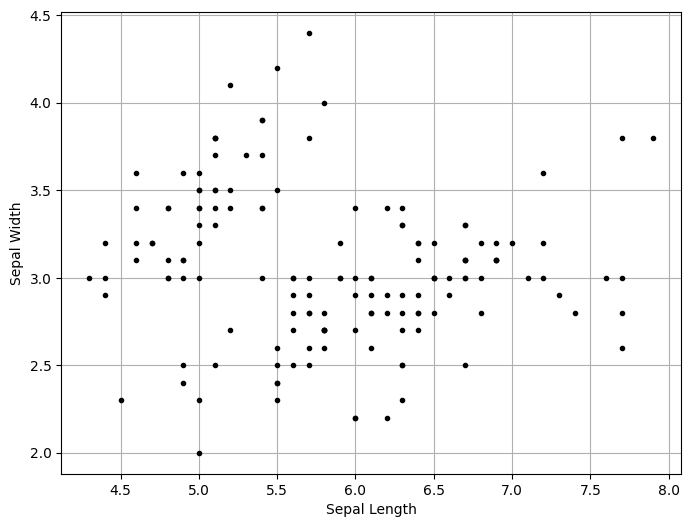

In [3]:
plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c="k",marker=".")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.gca().set_axisbelow(True)
plt.grid()
plt.show()

2. Gunakan Elbow Method dan model KMeans untuk mencari cluster terbaik.
   -

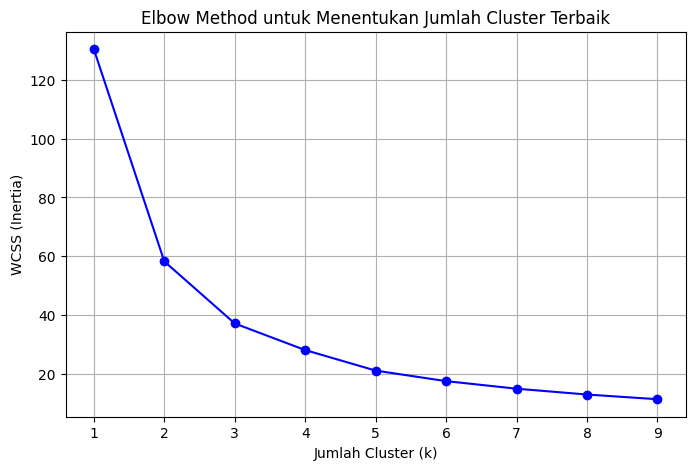

In [4]:
X_sepal = X[:, :2]
wcss = []
K_range = range(1, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_sepal)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='-', color='b')
plt.title("Elbow Method untuk Menentukan Jumlah Cluster Terbaik")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(K_range)
plt.grid(True)
plt.show()

In [5]:
k = 3
kmeans_sepal = KMeans(n_clusters=k, random_state=42, n_init=10)
y_pred = kmeans_sepal.fit_predict(X_sepal)
centroids = kmeans_sepal.cluster_centers_

print("Koordinat Centroid (Sepal Length, Sepal Width):")
print(centroids)

Koordinat Centroid (Sepal Length, Sepal Width):
[[6.81276596 3.07446809]
 [5.77358491 2.69245283]
 [5.006      3.428     ]]


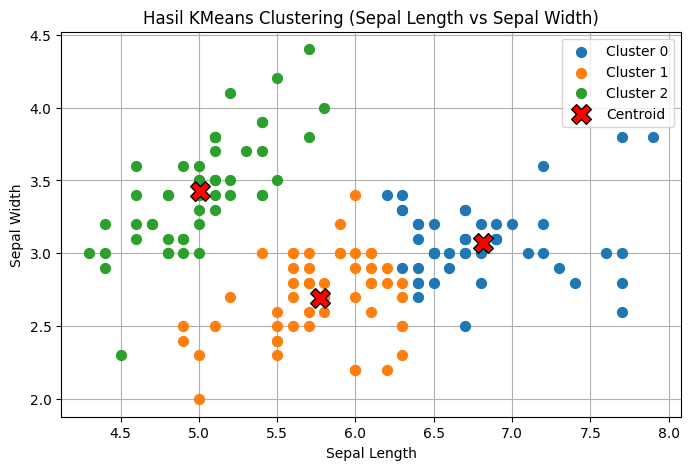

In [6]:
plt.figure(figsize=(8, 5))

for i in range(k):
    plt.scatter(
        X_sepal[y_pred == i, 0],
        X_sepal[y_pred == i, 1],
        s=50,
        label=f'Cluster {i}'
    )

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=200,
    c='red',
    marker='X',
    edgecolor='black',
    label='Centroid'
)

plt.title("Hasil KMeans Clustering (Sepal Length vs Sepal Width)")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.legend()
plt.gca().set_axisbelow(True)
plt.grid(True)
plt.show()

3. Bandingkan performa model dengan penggunaan fitur Petal Length dan Petal Width. Fitur mana yang paling baik dalam melakukan clustering?
   -

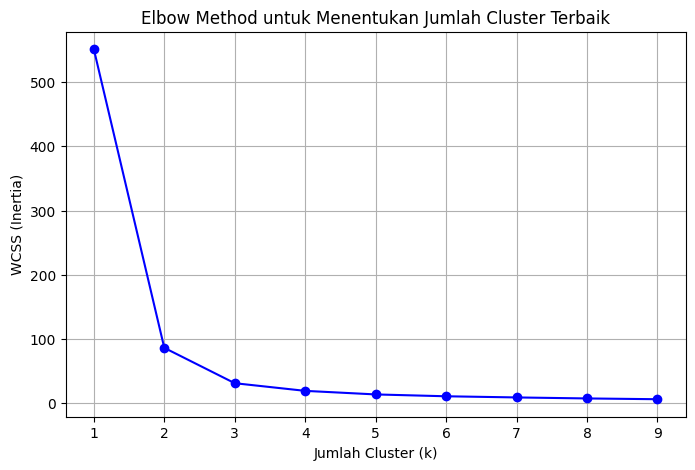

In [7]:
X_petal = X[:, 2:]
wcss = []
K_range = range(1, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_petal)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='-', color='b')
plt.title("Elbow Method untuk Menentukan Jumlah Cluster Terbaik")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(K_range)
plt.grid(True)
plt.show()

In [8]:
k = 3
kmeans_petal = KMeans(n_clusters=k)
y_pred = kmeans_petal.fit_predict(X_petal)
centroids = kmeans_petal.cluster_centers_

print("Koordinat Centroid (Petal Length, Petal Width):")
print(centroids)

Koordinat Centroid (Petal Length, Petal Width):
[[5.62608696 2.04782609]
 [1.462      0.246     ]
 [4.29259259 1.35925926]]


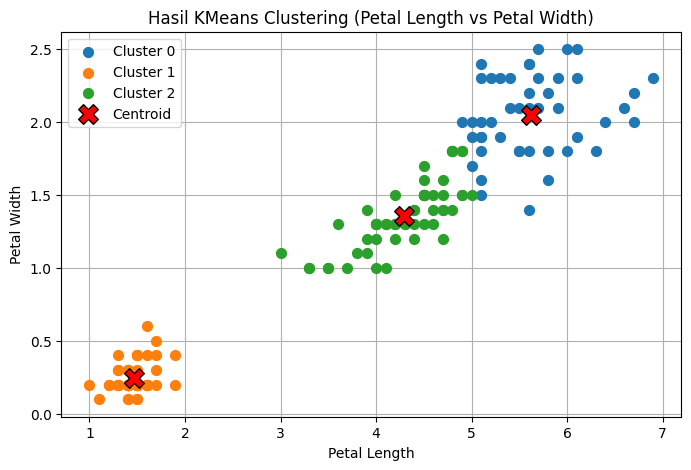

In [9]:
plt.figure(figsize=(8, 5))

for i in range(k):
    plt.scatter(
        X_petal[y_pred == i, 0],
        X_petal[y_pred == i, 1],
        s=50,
        label=f'Cluster {i}'
    )

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=200,
    c='red',
    marker='X',
    edgecolor='black',
    label='Centroid'
)

plt.title("Hasil KMeans Clustering (Petal Length vs Petal Width)")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.legend()
plt.gca().set_axisbelow(True)
plt.grid(True)
plt.show()

In [10]:
y_pred_sepal = kmeans_sepal.labels_
y_pred_petal = kmeans_petal.labels_

sil_sepal = silhouette_score(X_sepal, y_pred_sepal)
sil_petal = silhouette_score(X_petal, y_pred_petal)

print(f"Sepal -> Inertia: {kmeans_sepal.inertia_:.4f} | Silhouette Score: {sil_sepal:.4f}")
print(f"Petal -> Inertia: {kmeans_petal.inertia_:.4f} | Silhouette Score: {sil_petal:.4f}")

Sepal -> Inertia: 37.0507 | Silhouette Score: 0.4451
Petal -> Inertia: 31.4129 | Silhouette Score: 0.6603


Berdasarkan hasil evaluasi, penggunaan fitur Petal Length dan Petal Width menghasilkan performa clustering yang lebih baik dibandingkan fitur Sepal. Hal ini dikarenakan nilai Silhouette Score fitur Petal (0.6605) yang lebih tinggi daripada fitur Sepal (0.4451), serta nilai inertia yang lebih rendah (~31.37 vs ~37.05). Secara visual, cluster pada fitur Petal juga terpisah jauh lebih tegas dengan tumpang tindih (overlap) yang minim.

4. Lakukan eksperimen KMeans Clustering dengan menggunakan keempat fitur dataset Iris. Apakah performa model meningkat, menurun, atau tetap?
   -

In [11]:
kmeans_all = KMeans(n_clusters=3, random_state=42, n_init=10)
y_pred_all = kmeans_all.fit_predict(X)

sil_all = silhouette_score(X, y_pred_all)

print(f"All       -> Inertia: {kmeans_all.inertia_:.4f} | Silhouette Score: {sil_all:.4f}")
print(f"Sepal     -> Inertia: {kmeans_sepal.inertia_:.4f} | Silhouette Score: {sil_sepal:.4f}")
print(f"Petal     -> Inertia: {kmeans_petal.inertia_:.4f} | Silhouette Score: {sil_petal:.4f}")

All       -> Inertia: 78.8514 | Silhouette Score: 0.5528
Sepal     -> Inertia: 37.0507 | Silhouette Score: 0.4451
Petal     -> Inertia: 31.4129 | Silhouette Score: 0.6603


Jika keempat fitur (All) dibandingkan fitur Sepal saja, performa model meningkat (Silhouette Score naik dari 0.4451 menjadi 0.5528). Jika keempat fitur dibandingkan dengan fitur Petal saja, performa model malah menurun (Silhouette Score turun dari 0.6605 menjadi 0.5528).

5. Lakukan eksperimen DBSCAN yang membandingkan fitur Petal, Sepal, dan keduanya pada dataset Iris. Bagaimana performa model DBSCAN pada perubahan fitur yang digunakan?
   -

[Sepal (2 Fitur)] Cluster: 1 | Noise: 2 | Silhouette: N/A (< 2 cluster)
[Petal (2 Fitur)] Cluster: 2 | Noise: 0 | Silhouette: 0.7669
[All (4 Fitur)] Cluster: 2 | Noise: 17 | Silhouette: 0.4860


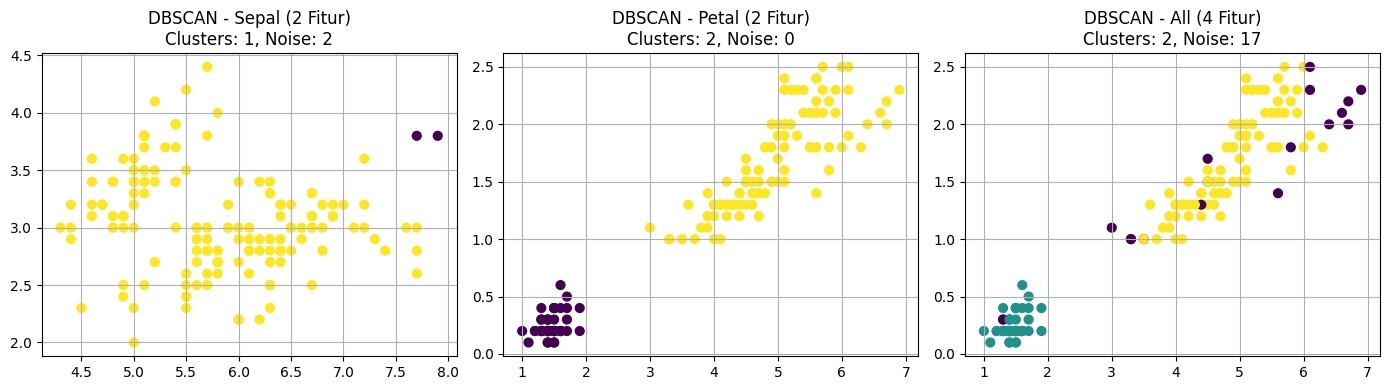

In [12]:
datasets = {
    "Sepal (2 Fitur)": X_sepal,
    "Petal (2 Fitur)": X_petal,
    "All (4 Fitur)": X
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, data) in zip(axes, datasets.items()):
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    labels = dbscan.fit_predict(data)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    
    if n_clusters >= 2:
        sil = silhouette_score(data, labels)
        sil_text = f"{sil:.4f}"
    else:
        sil_text = "N/A (< 2 cluster)"
        
    print(f"[{name}] Cluster: {n_clusters} | Noise: {n_noise} | Silhouette: {sil_text}")
    
    x_plot = data[:, 2] if data.shape[1] == 4 else data[:, 0]
    y_plot = data[:, 3] if data.shape[1] == 4 else data[:, 1]
    
    scatter = ax.scatter(x_plot, y_plot, c=labels, cmap='viridis', s=40)
    ax.set_title(f"DBSCAN - {name}\nClusters: {n_clusters}, Noise: {n_noise}")
    ax.grid(True)

plt.tight_layout()
plt.show()

- Fitur Petal: Performa paling baik (Silhouette Score 0.7669, noise-nya nol).

- Fitur Sepal: Performa paling buruk. Karena sebaran data Sepal rapat dan saling tumpang tindih, dengan eps=0.5 DBSCAN gagal memisahkan cluster dengan baik (sering kali hanya membentuk 1 cluster besar + beberapa titik noise).

- All (4 Fitur): Tetap membentuk 2 cluster utama, tetapi jumlah noise meningkat drastis (sekitar 17 titik) dan Silhouette Score menurun (~0.48). Ini terjadi karena penambahan dimensi membuat jarak antar titik di ruang 4D semakin renggang (curse of dimensionality), sehingga banyak titik yang tidak lagi memenuhi radius eps=0.5.

6. Lakukan eksperimen Agglomerative Clustering pada dataset Iris. Pemilihan fitur dibebaskan dengan diberikan justifikasinya. Bagaimana hasil model Agglomerative Clustering pada eksperimen tersebut?
   -

Agglomerative Clustering (Petal) -> Silhouette Score: 0.6574


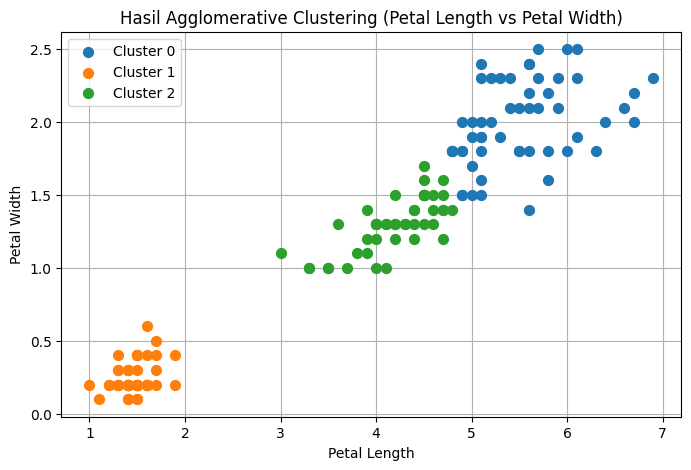

In [13]:
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
y_pred_agg = agg.fit_predict(X_petal)

sil_agg = silhouette_score(X_petal, y_pred_agg)
print(f"Agglomerative Clustering (Petal) -> Silhouette Score: {sil_agg:.4f}")

# Visualisasi hasil
plt.figure(figsize=(8, 5))
for i in range(3):
    plt.scatter(
        X_petal[y_pred_agg == i, 0],
        X_petal[y_pred_agg == i, 1],
        s=50,
        label=f'Cluster {i}'
    )

plt.title("Hasil Agglomerative Clustering (Petal Length vs Petal Width)")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.legend()
plt.gca().set_axisbelow(True)
plt.grid(True)
plt.show()

- Justifikasi Pemilihan Fitur: Fitur yang dipilih adalah Petal Length dan Petal Width karena berdasarkan eksperimen KMeans (No. 3 & 4) dan DBSCAN (No. 5), kedua fitur ini terbukti memiliki pemisahan antar kelas yang paling tegas, Silhouette Score tertinggi, dan paling minim overlap dibandingkan fitur Sepal maupun gabungan 4 fitur.

- Hasil Eksperimen: Model Agglomerative Clustering (n_clusters=3, linkage='ward') menghasilkan performa yang sangat baik dengan Silhouette Score sekitar 0.65–0.66, hampir setara dengan KMeans pada fitur yang sama. Secara visual, ketiga cluster terbentuk dengan sangat rapi dan proporsional tanpa ada noise, di mana satu cluster terpisah sempurna di kiri bawah (Setosa) dan dua cluster lainnya terbagi tegas di area tengah hingga kanan atas (Versicolor dan Virginica).